In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [56]:
d1 = find_file("240510_TS_C10_W20_run3.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d3 = find_file("240510_TS_C10_W20_run4.DSC", exp_type="francklab_esr/romana") # cooling 2 subsequently --after cooling and heating
d2 = find_file("240510_TS_C10_W20_run5", exp_type="francklab_esr/romana") #heating

In [57]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [58]:
d2.shape

[(1024, '$B_0$'), (41, 'Temperature'), (10, 'harmonic')]

In [59]:
d3.shape

[(1024, '$B_0$'), (10, 'Temperature'), (10, 'harmonic')]

In [60]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [61]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (41, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [62]:
d3.chunk_auto("harmonic", "harmonic")
d3.shape

[(1024, '$B_0$'), (10, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling 2.1')

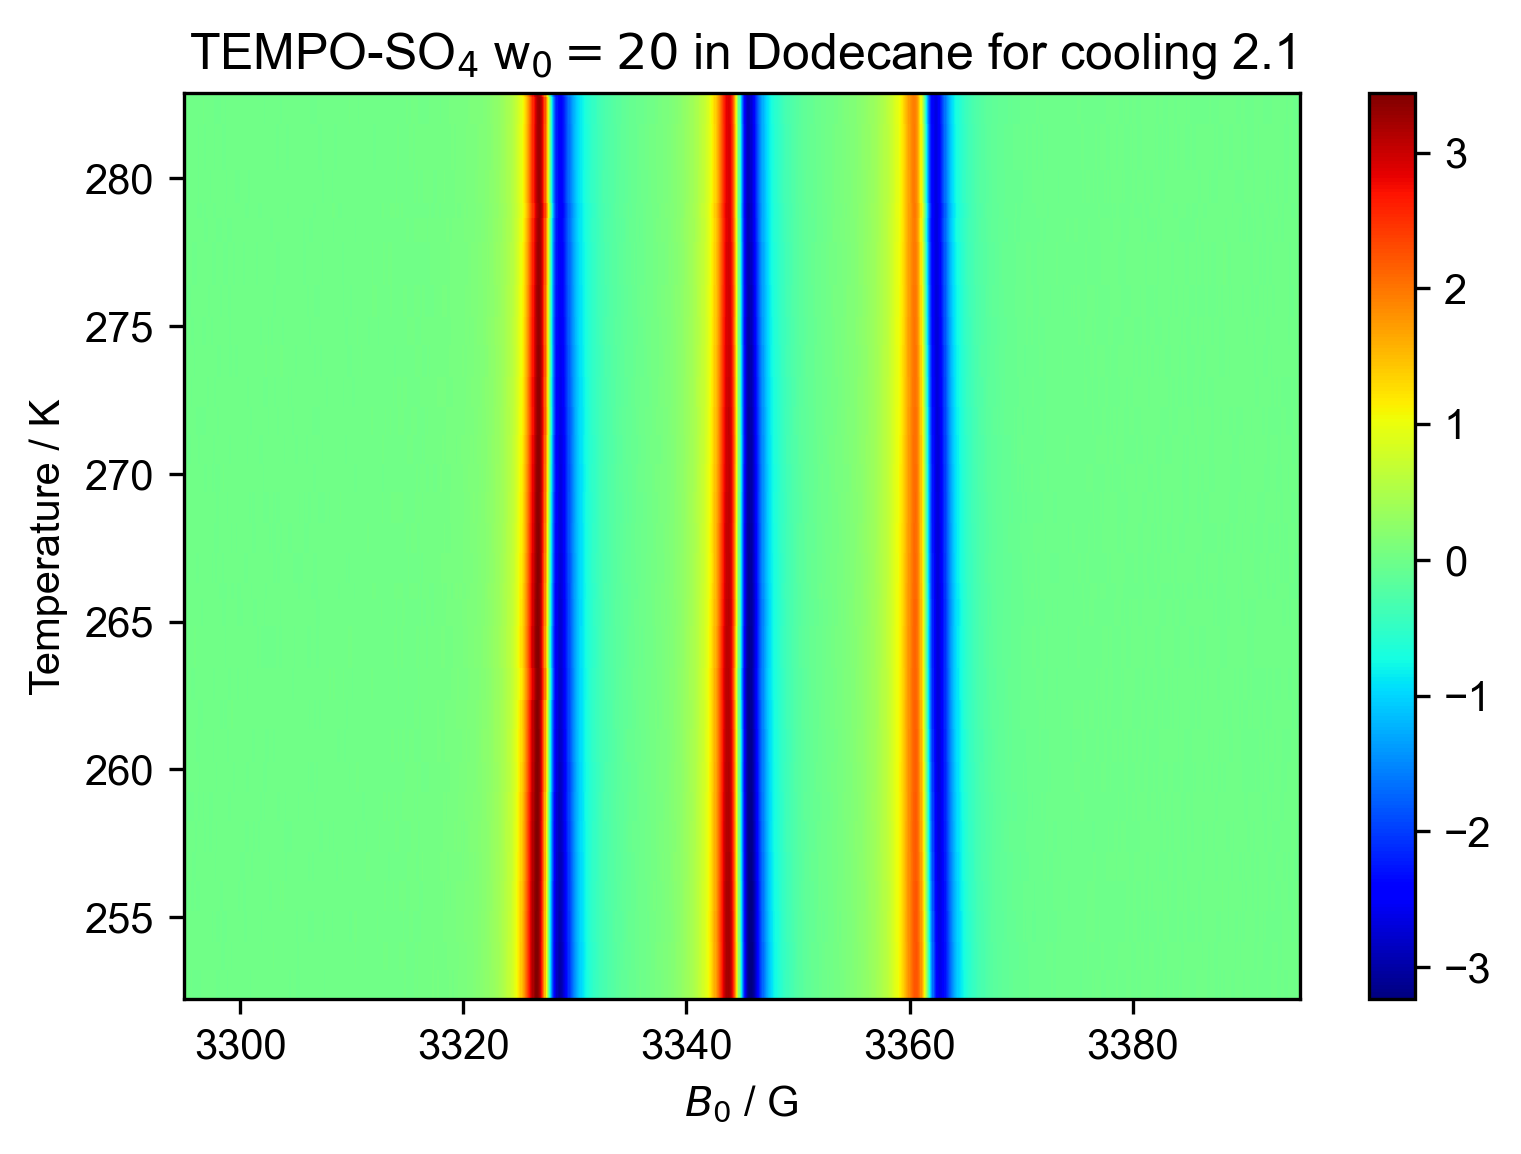

In [63]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling 2.1")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling 2.2')

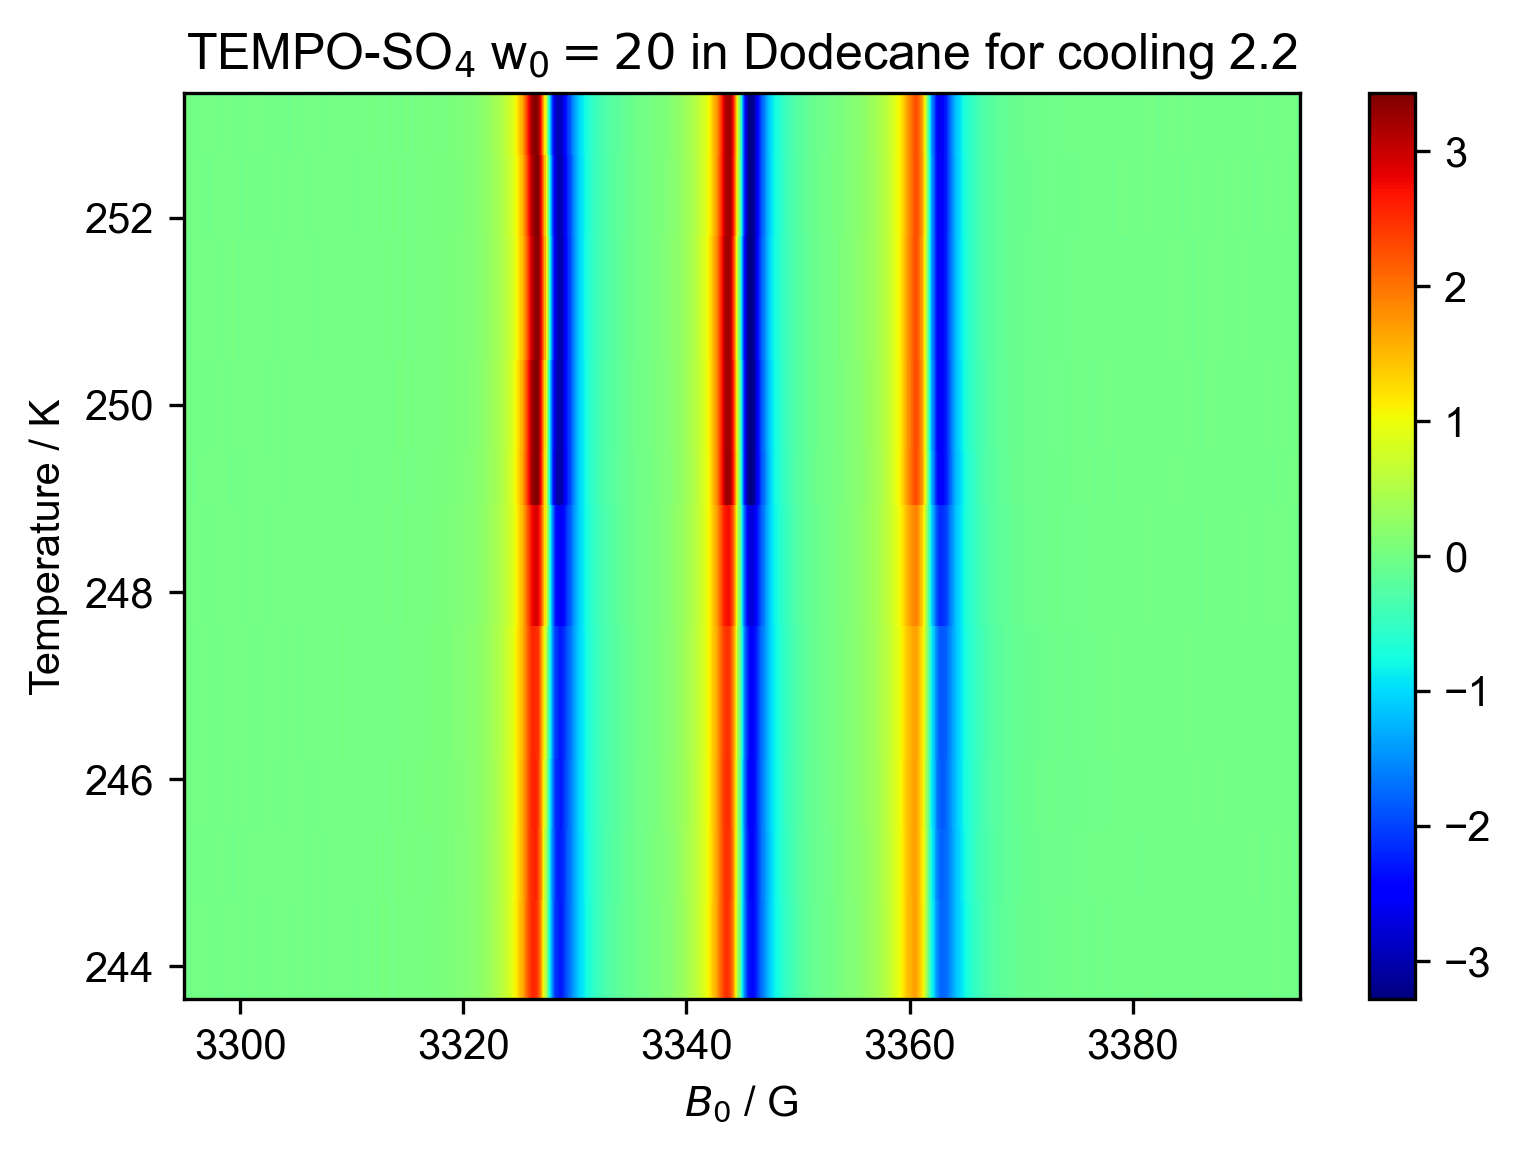

In [64]:
figure(dpi=300)
d3 = d3["harmonic", 0]["phase", 0]
d3.sort('Temperature')
d3.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling 2.2")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for heating 2')

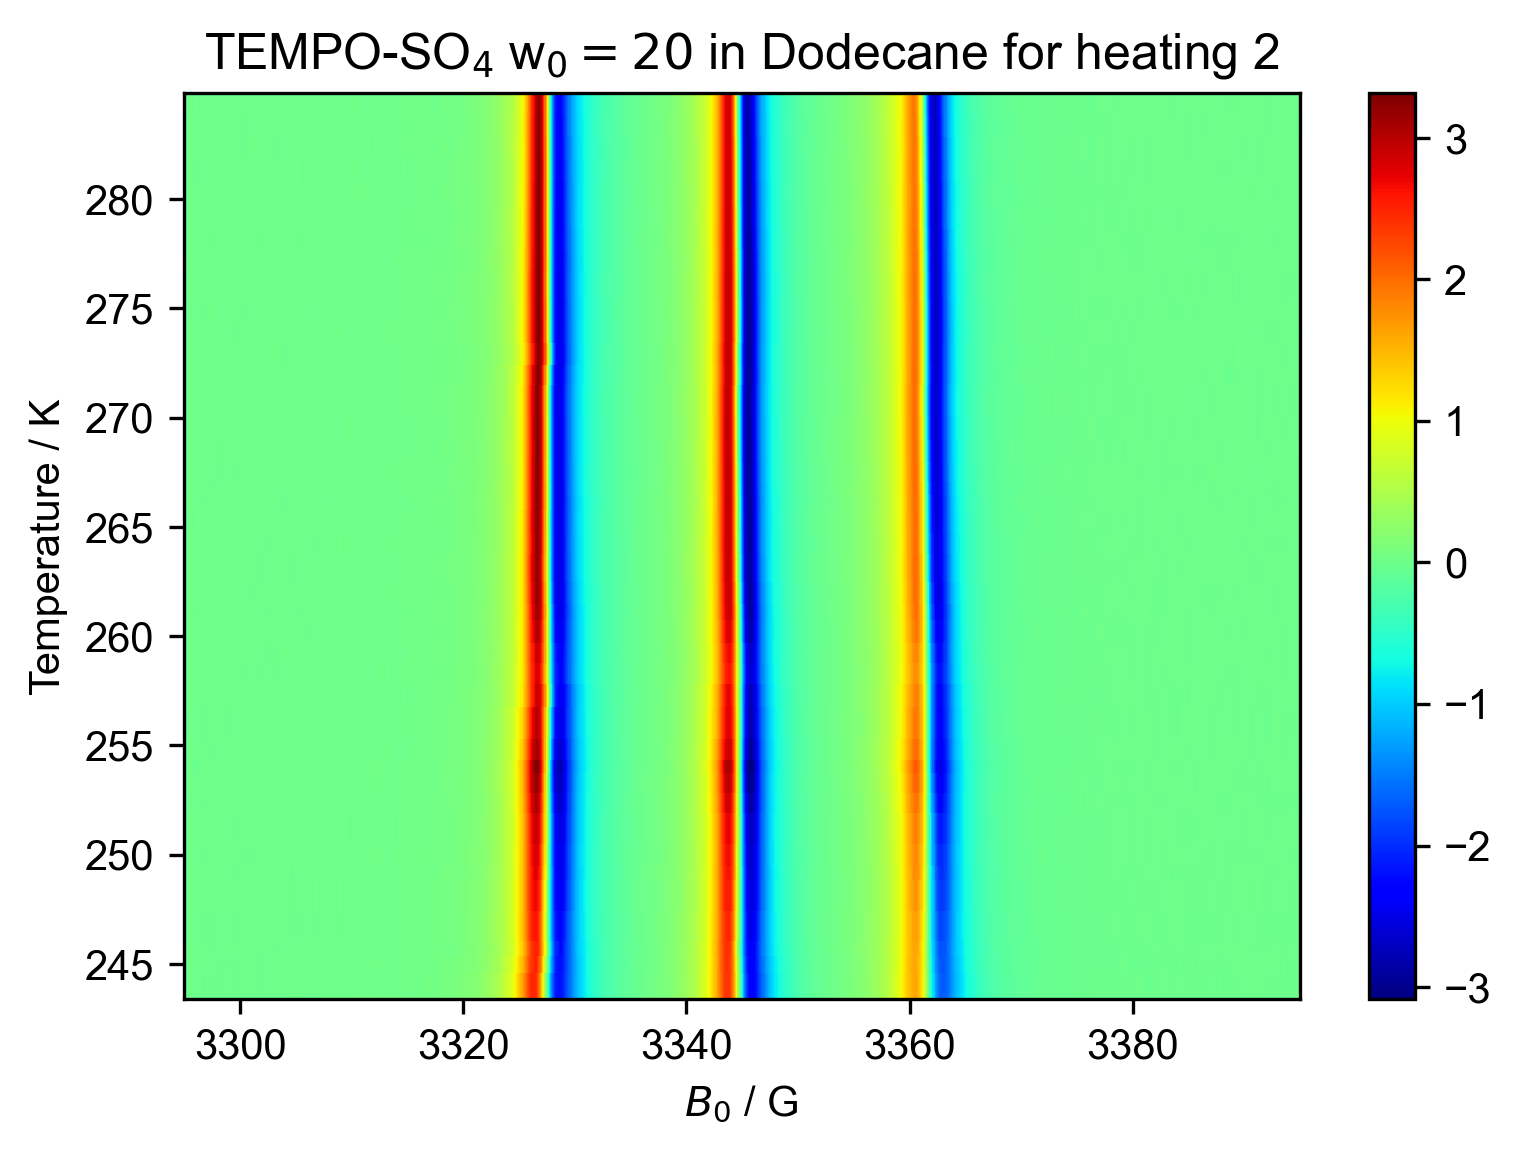

In [65]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for heating 2")

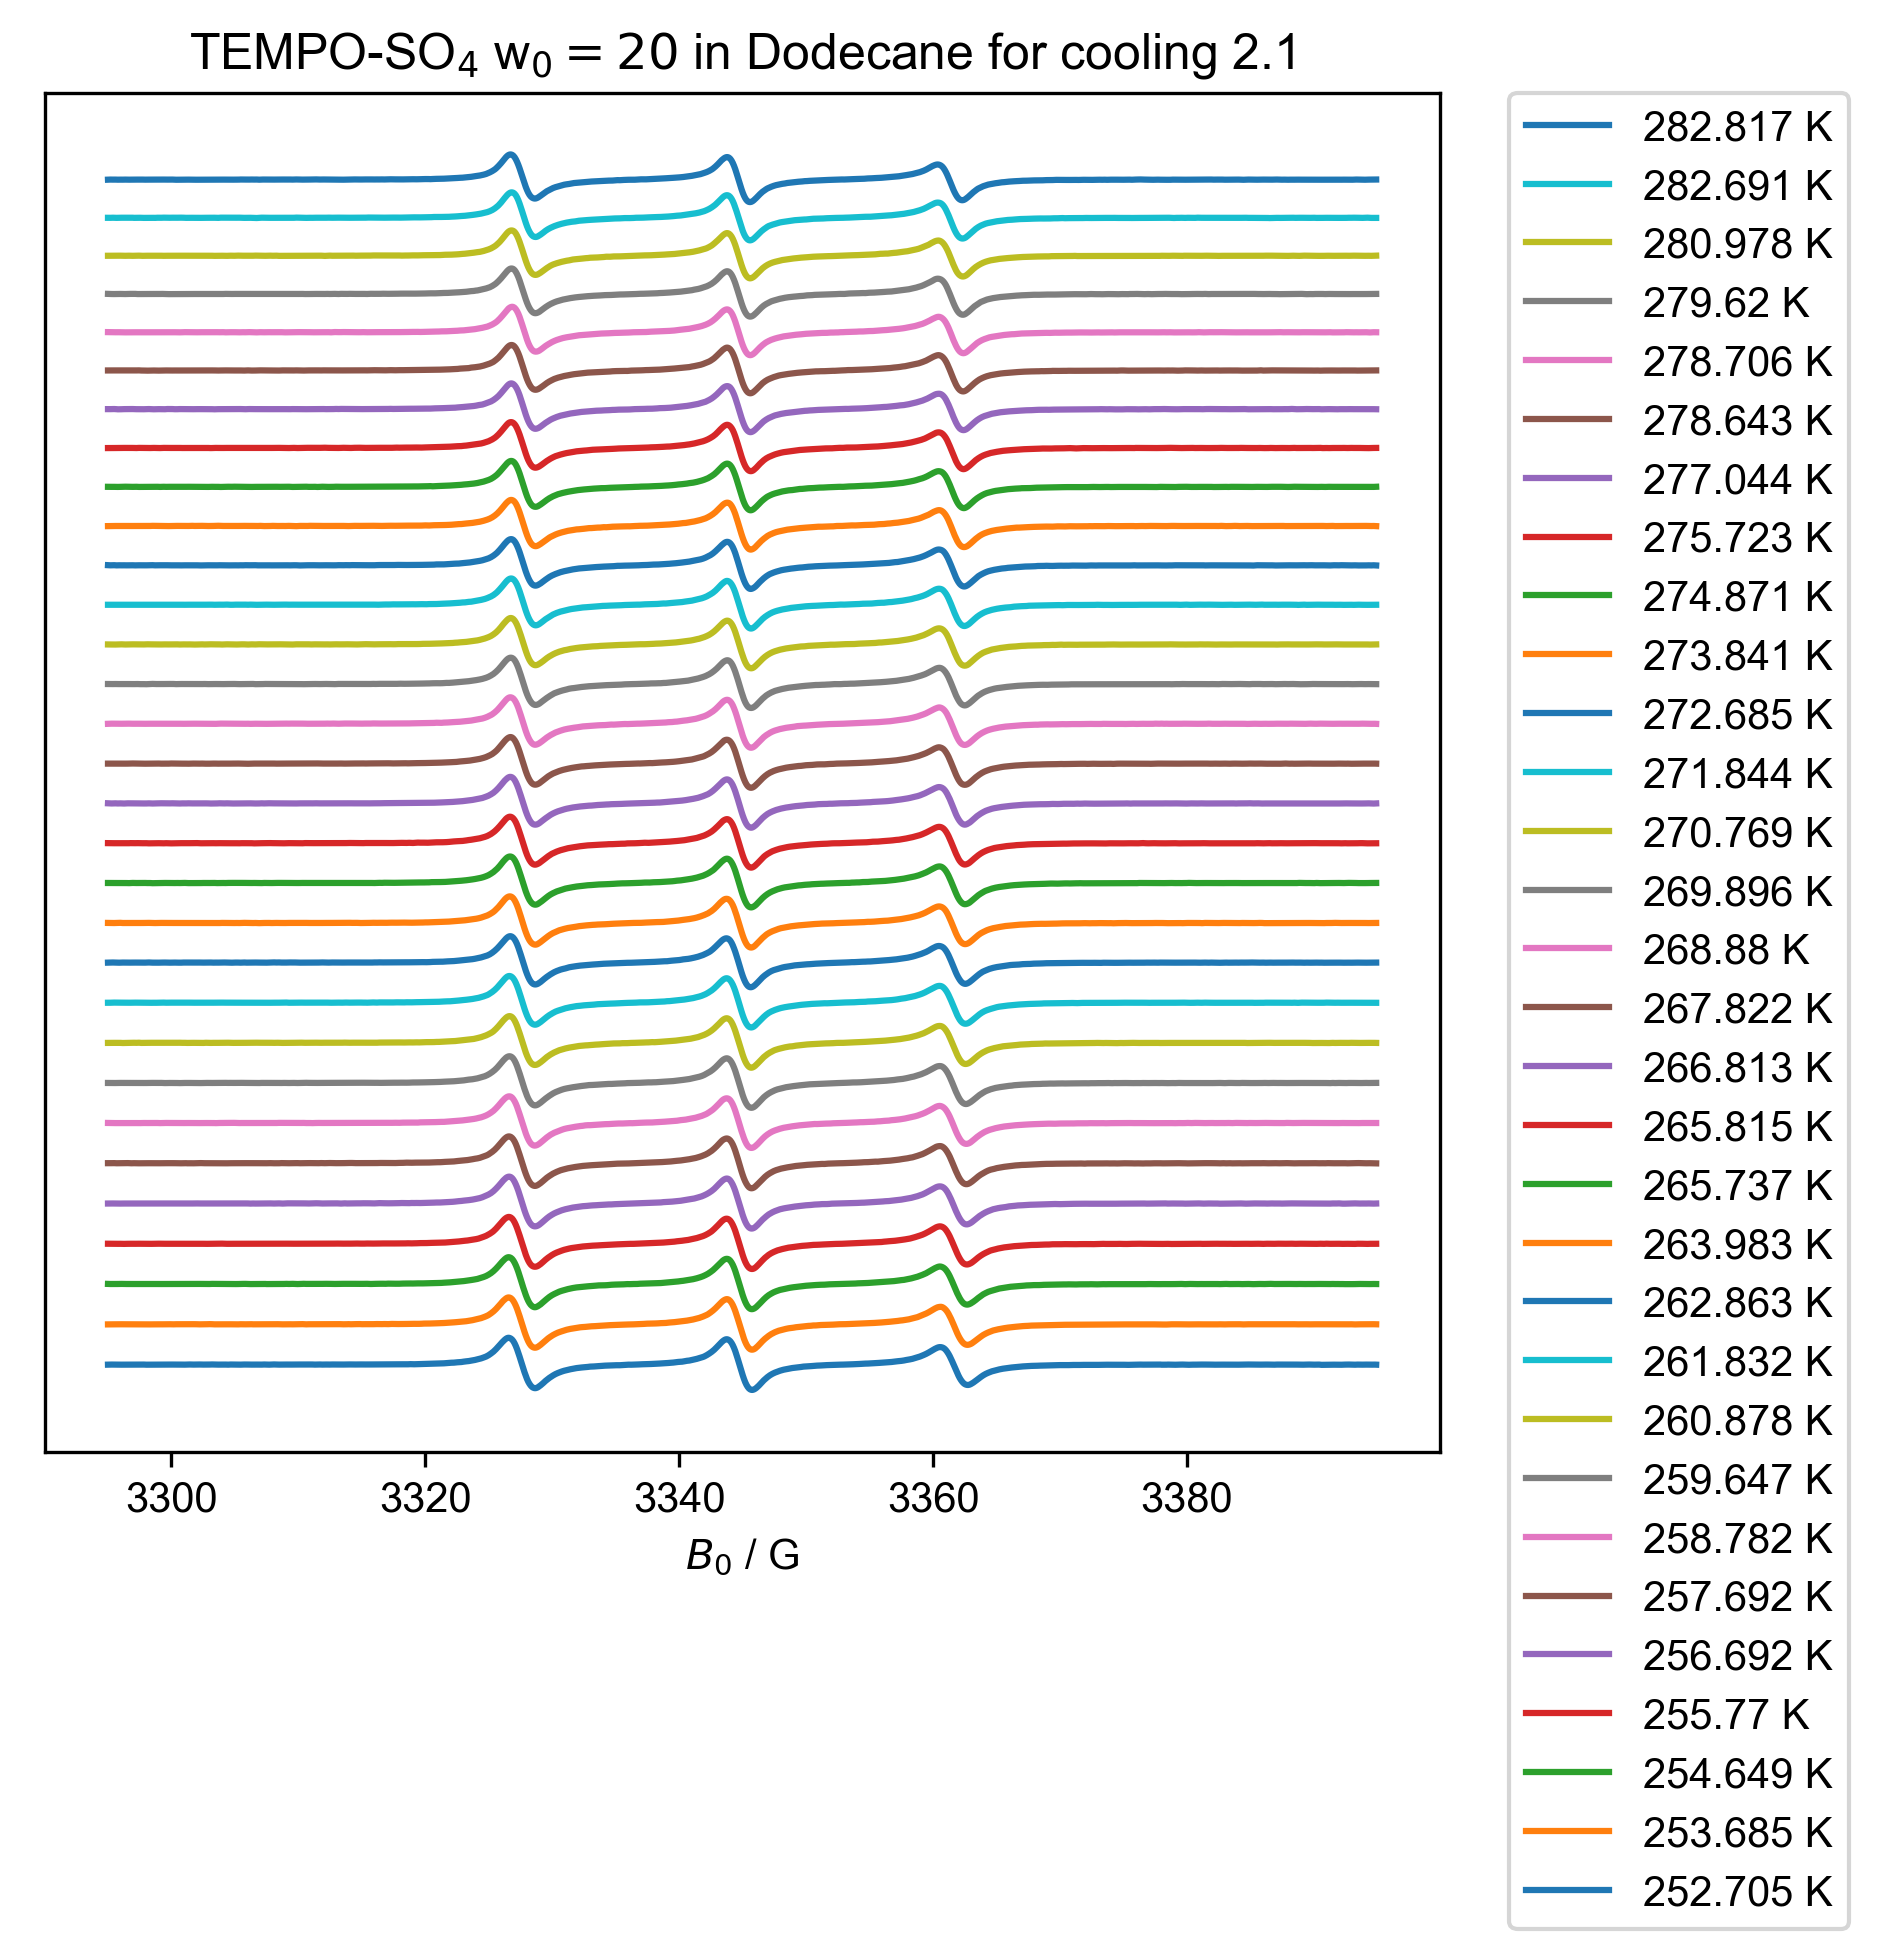

In [66]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling 2.1", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

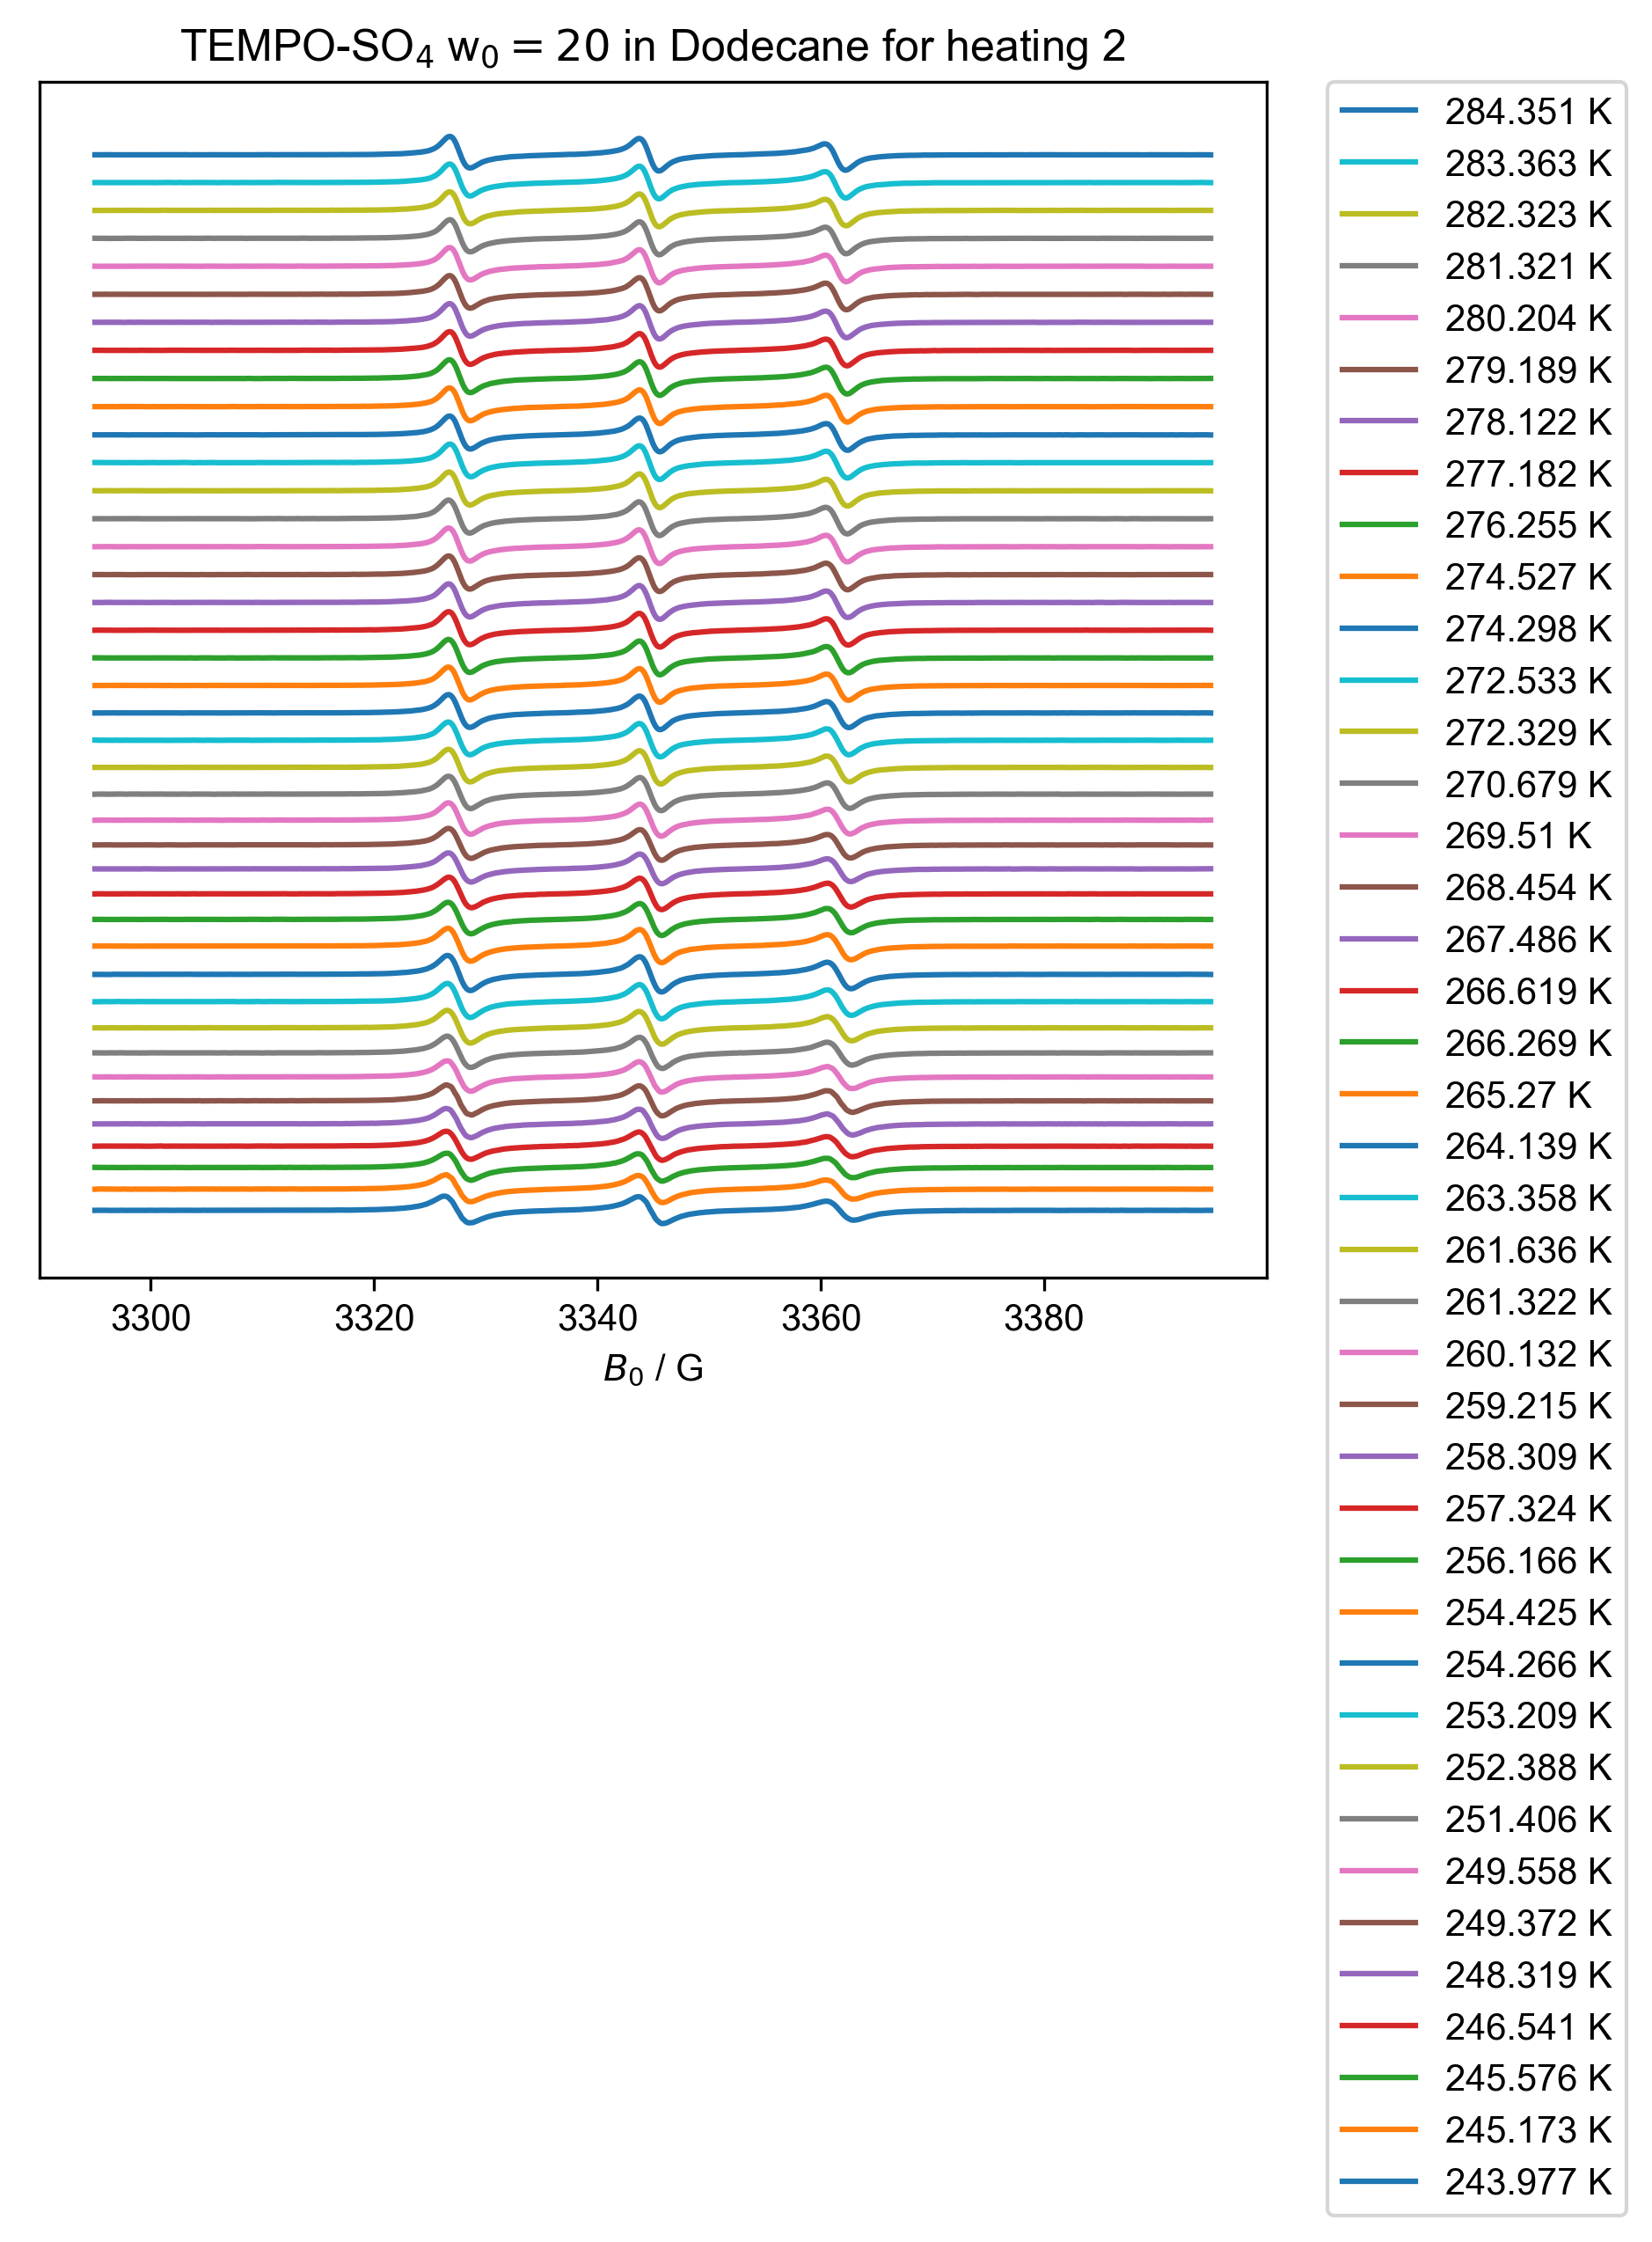

In [67]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating 2", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[252.705 253.685 254.649 255.77  256.692 257.692 258.782 259.647 260.878
 261.832 262.863 263.983 265.737 265.815 266.813 267.822 268.88  269.896
 270.769 271.844 272.685 273.841 274.871 275.723 277.044 278.643 278.706
 279.62  280.978 282.691 282.817]
[243.977 245.173 245.576 246.541 248.319 249.372 249.558 251.406 252.388
 253.209 254.266 254.425 256.166 257.324 258.309 259.215 260.132 261.322
 261.636 263.358 264.139 265.27  266.269 266.619 267.486 268.454 269.51
 270.679 272.329 272.533 274.298 274.527 276.255 277.182 278.122 279.189
 280.204 281.321 282.323 283.363 284.351]


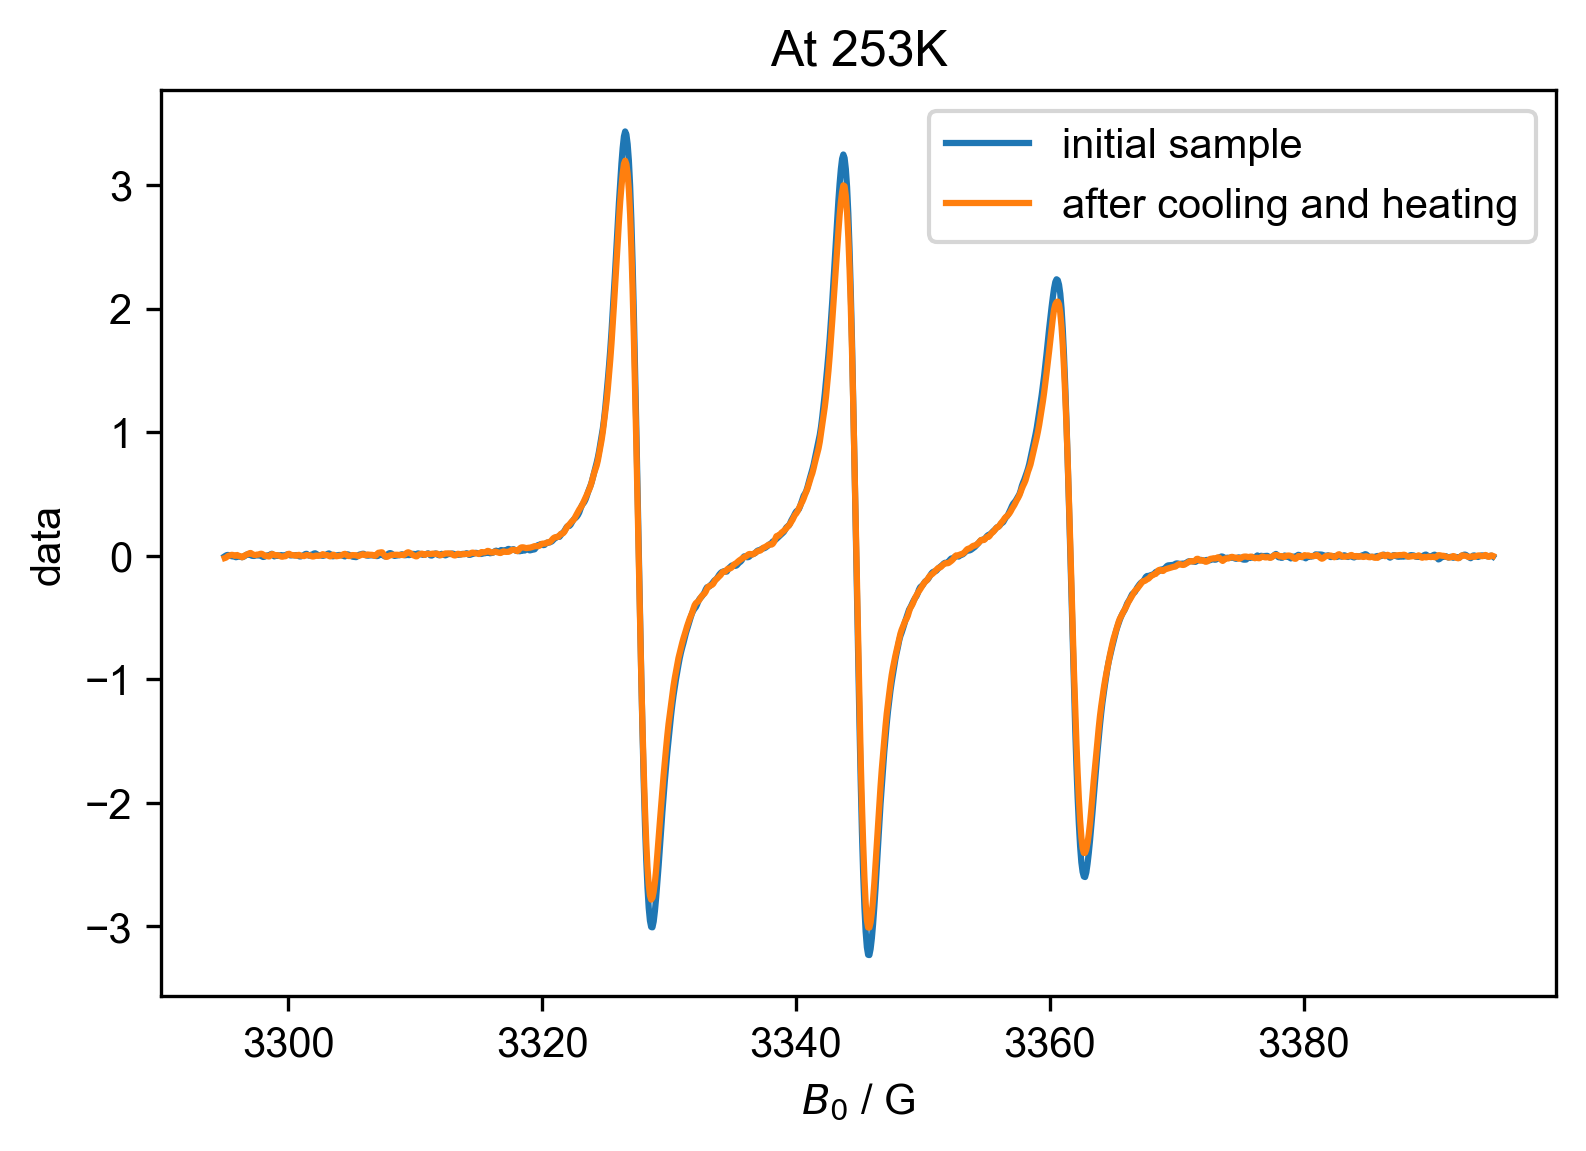

In [68]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[252.705 253.685 254.649 255.77  256.692 257.692 258.782 259.647 260.878
 261.832 262.863 263.983 265.737 265.815 266.813 267.822 268.88  269.896
 270.769 271.844 272.685 273.841 274.871 275.723 277.044 278.643 278.706
 279.62  280.978 282.691 282.817]
[243.977 245.173 245.576 246.541 248.319 249.372 249.558 251.406 252.388
 253.209 254.266 254.425 256.166 257.324 258.309 259.215 260.132 261.322
 261.636 263.358 264.139 265.27  266.269 266.619 267.486 268.454 269.51
 270.679 272.329 272.533 274.298 274.527 276.255 277.182 278.122 279.189
 280.204 281.321 282.323 283.363 284.351]


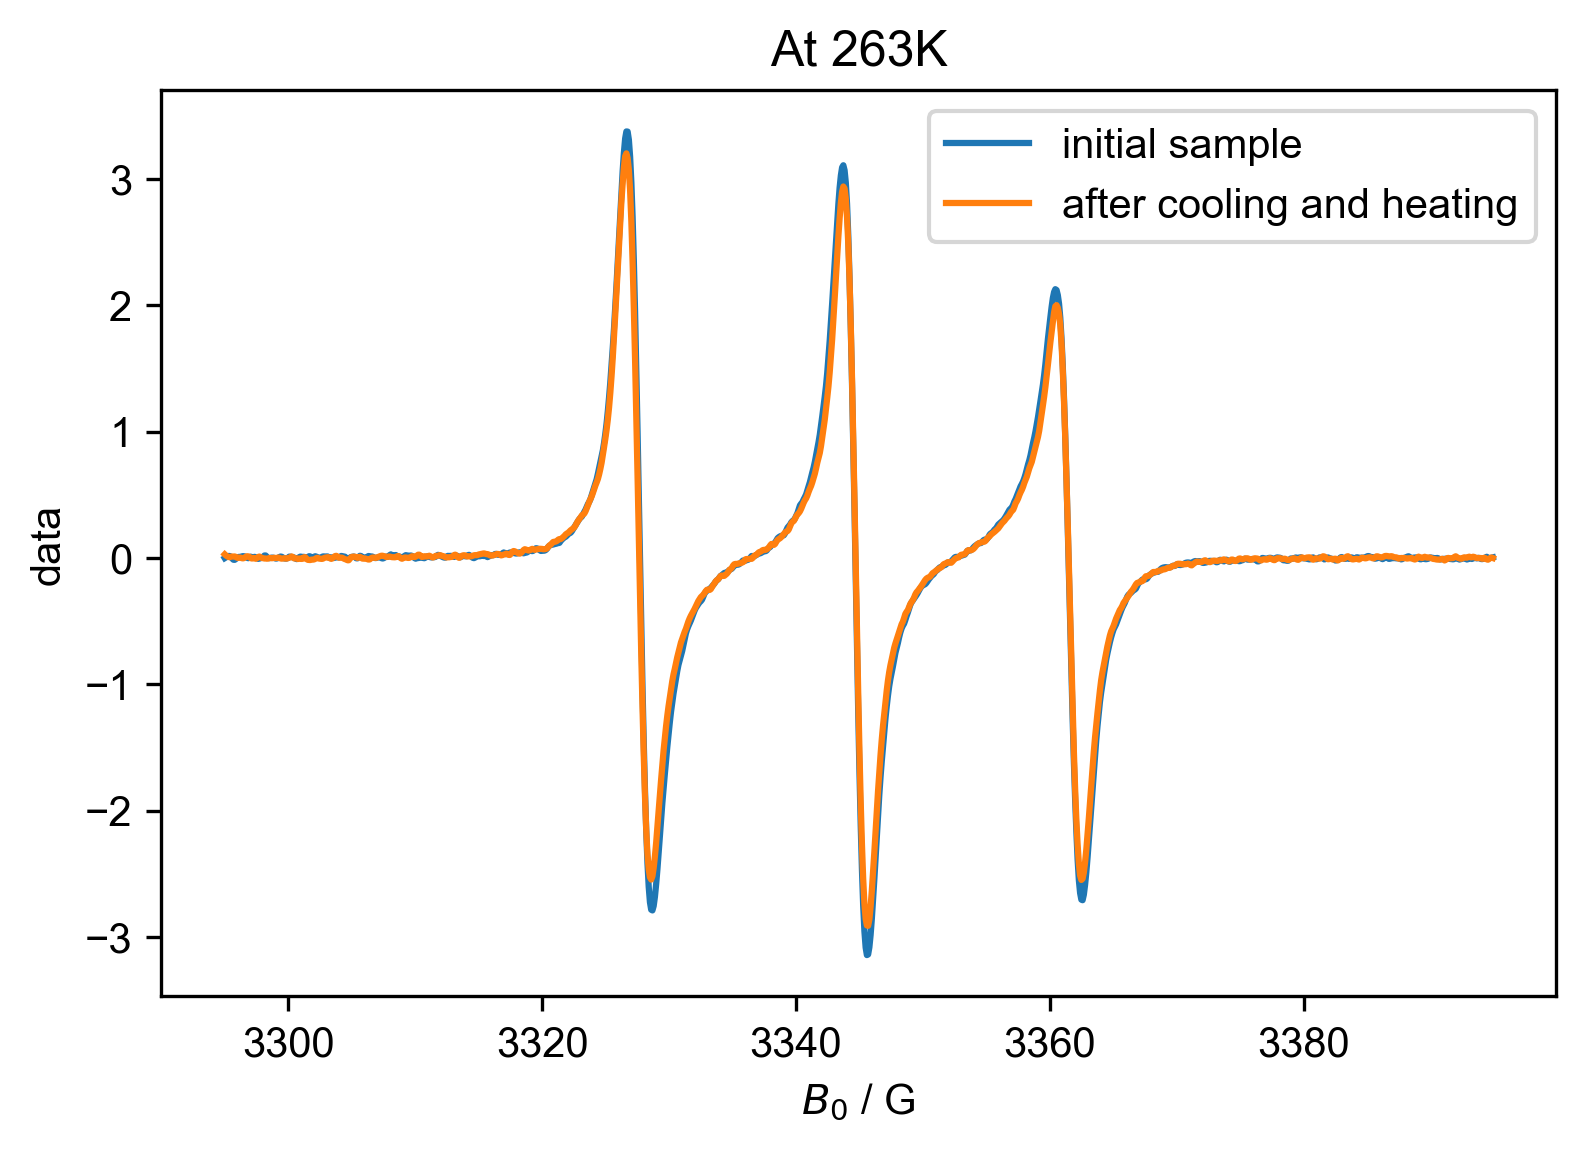

In [69]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[252.705 253.685 254.649 255.77  256.692 257.692 258.782 259.647 260.878
 261.832 262.863 263.983 265.737 265.815 266.813 267.822 268.88  269.896
 270.769 271.844 272.685 273.841 274.871 275.723 277.044 278.643 278.706
 279.62  280.978 282.691 282.817]
[243.977 245.173 245.576 246.541 248.319 249.372 249.558 251.406 252.388
 253.209 254.266 254.425 256.166 257.324 258.309 259.215 260.132 261.322
 261.636 263.358 264.139 265.27  266.269 266.619 267.486 268.454 269.51
 270.679 272.329 272.533 274.298 274.527 276.255 277.182 278.122 279.189
 280.204 281.321 282.323 283.363 284.351]


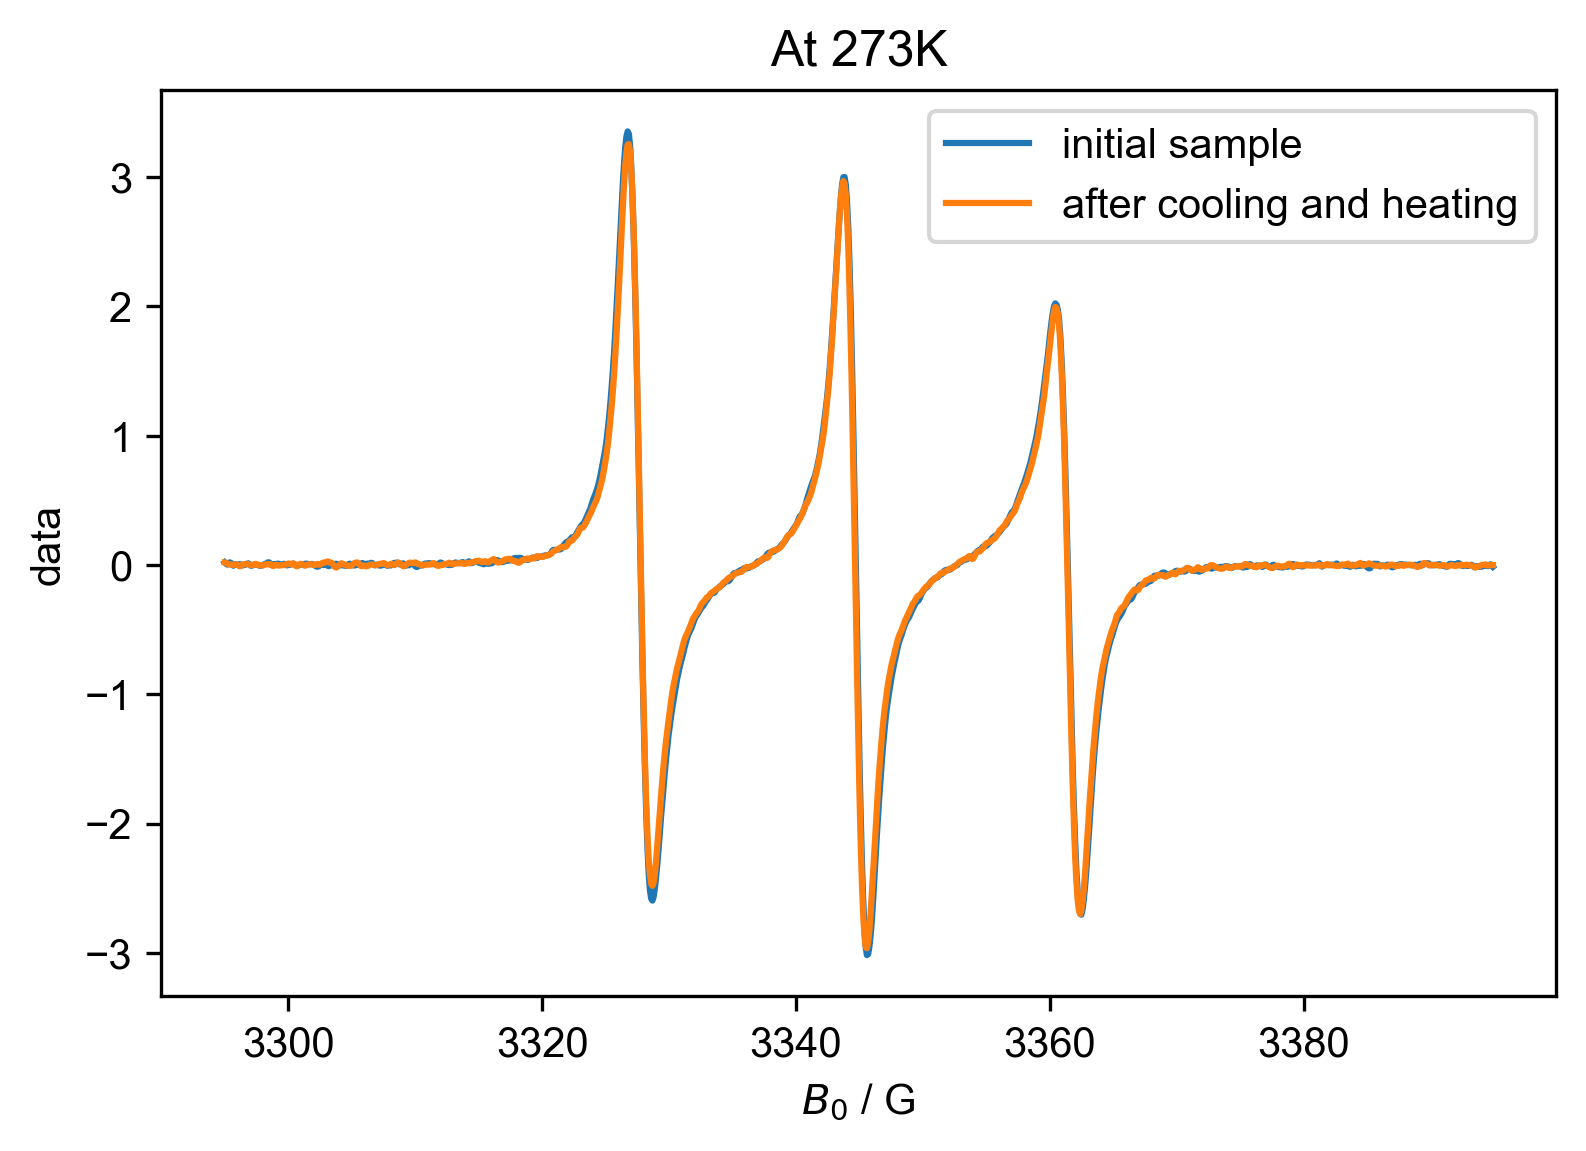

In [70]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[252.705 253.685 254.649 255.77  256.692 257.692 258.782 259.647 260.878
 261.832 262.863 263.983 265.737 265.815 266.813 267.822 268.88  269.896
 270.769 271.844 272.685 273.841 274.871 275.723 277.044 278.643 278.706
 279.62  280.978 282.691 282.817]
[243.977 245.173 245.576 246.541 248.319 249.372 249.558 251.406 252.388
 253.209 254.266 254.425 256.166 257.324 258.309 259.215 260.132 261.322
 261.636 263.358 264.139 265.27  266.269 266.619 267.486 268.454 269.51
 270.679 272.329 272.533 274.298 274.527 276.255 277.182 278.122 279.189
 280.204 281.321 282.323 283.363 284.351]


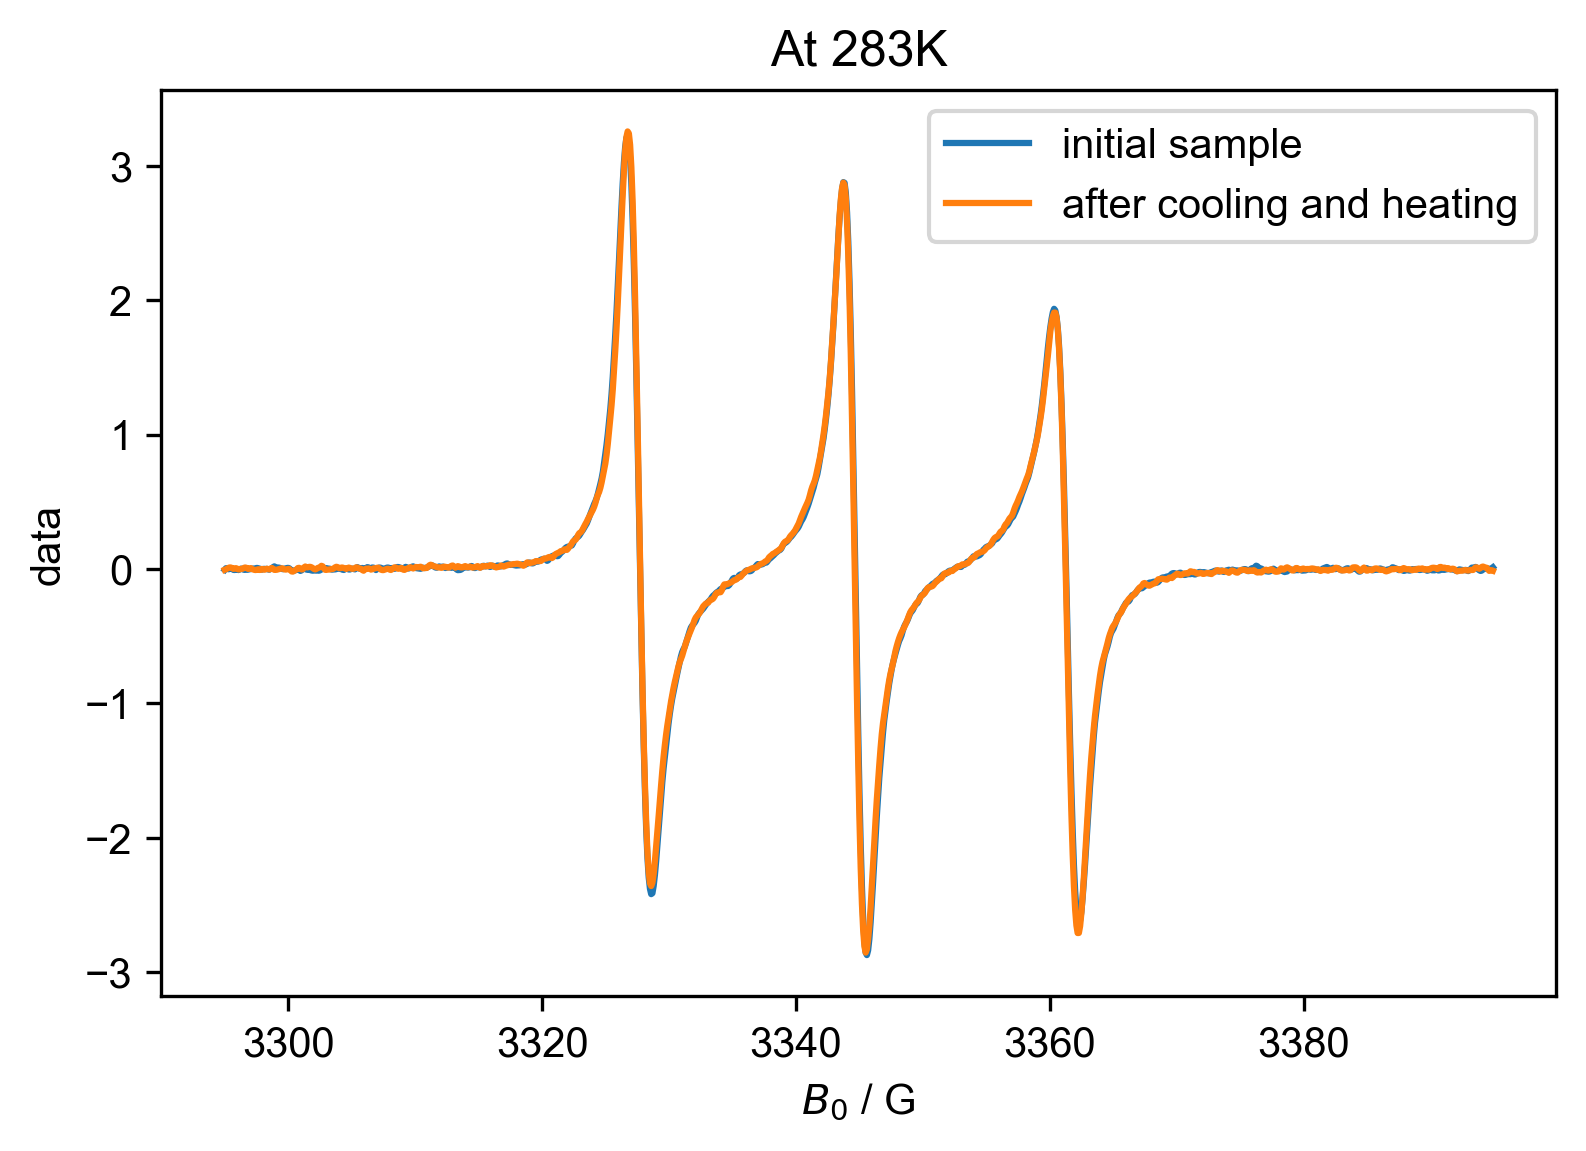

In [71]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

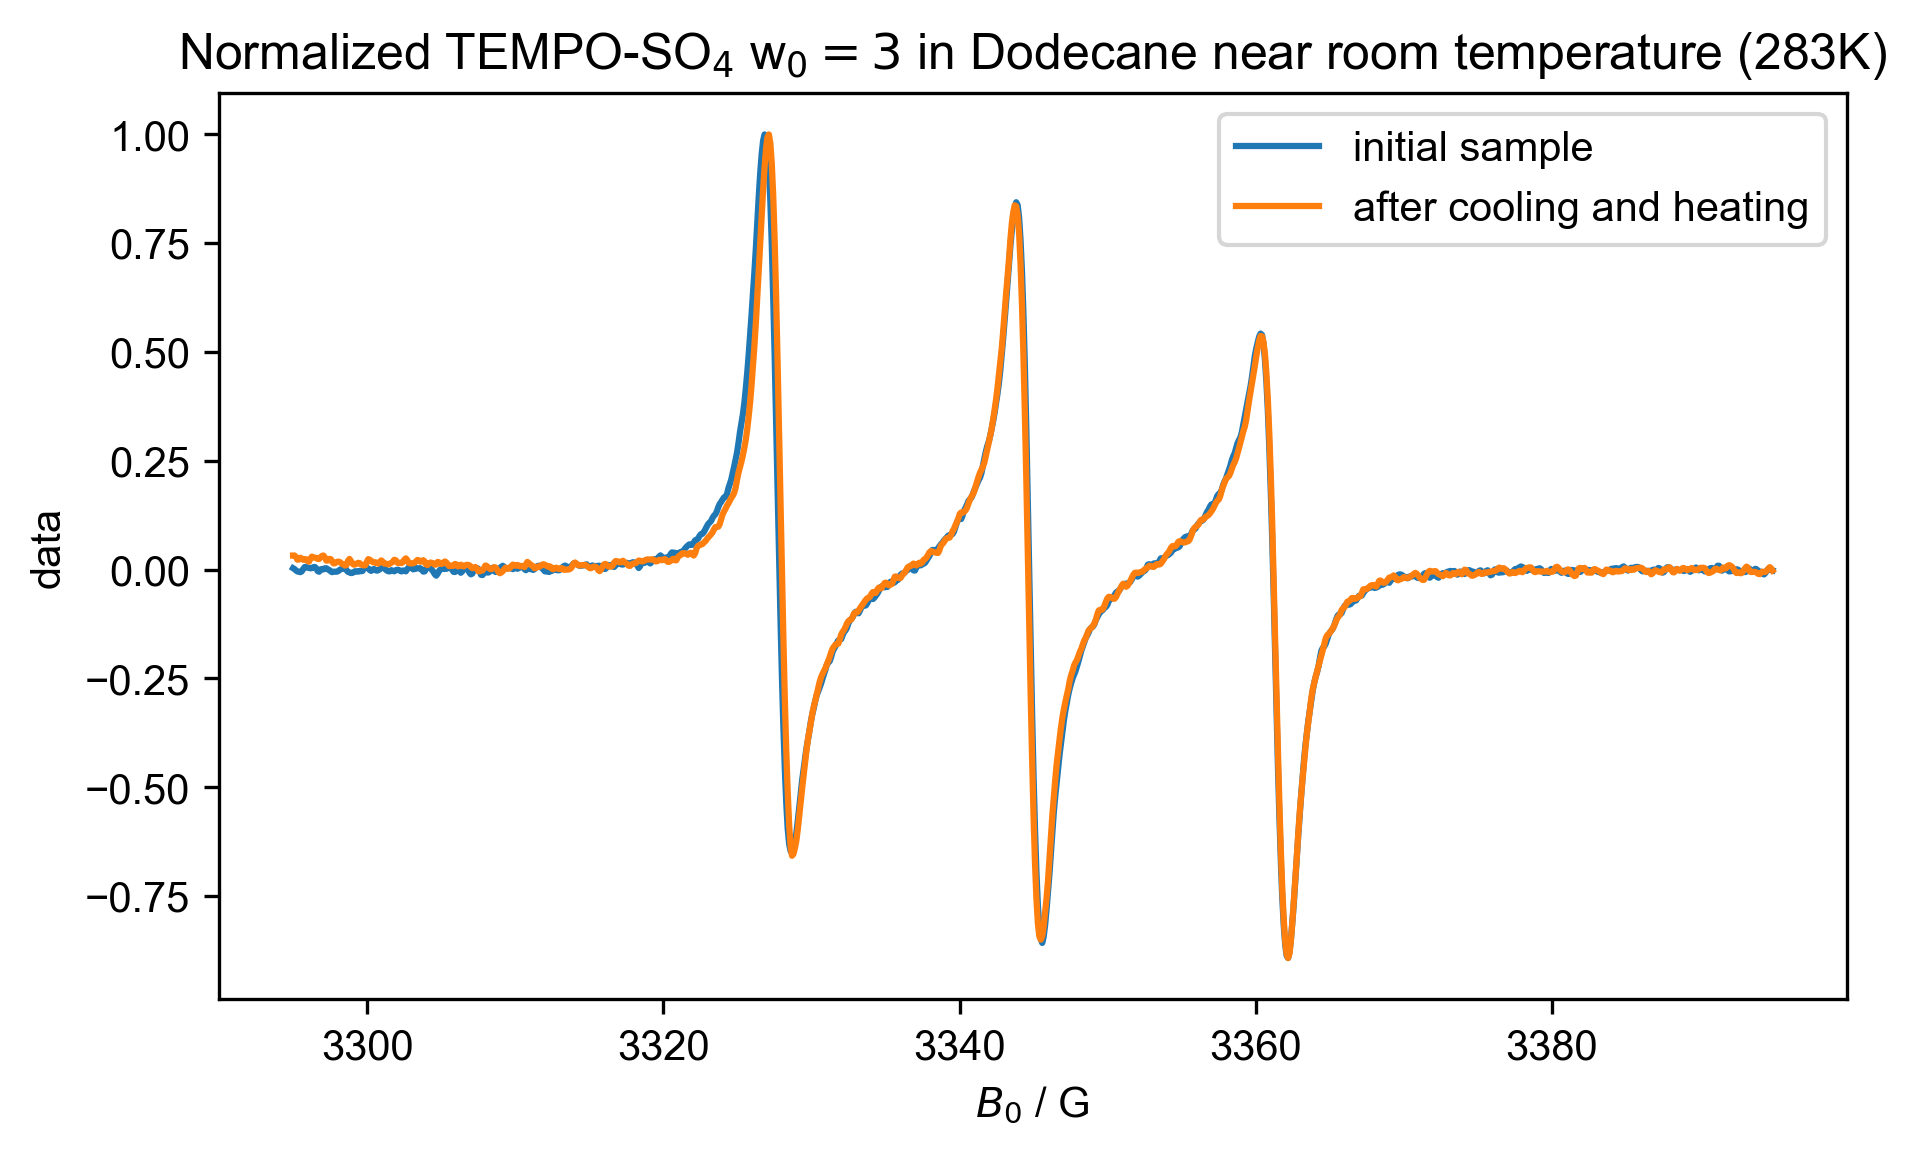

In [15]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 3$ in Dodecane near room temperature (283K)")
legend()